# 04 · Final Evaluation, Summary Table & Plots

From `code/evaluate.py`. Loads every saved checkpoint, runs one deterministic evaluation year per method × seed,
and produces:

1. `01_notebook_pipeline/results/tables/evaluation_raw_results.csv` — one row per method × seed
2. `01_notebook_pipeline/results/tables/summary_table.{csv,md}` — mean ± std over seeds, CO₂ avoided vs RBC, self-consumption
3. `01_notebook_pipeline/results/plots/pareto_frontier.png` — cost vs carbon
4. `01_notebook_pipeline/results/plots/training_curves.png` — episode reward during training, mean ± std over seeds

Evaluation is independent of training: it only needs the `.zip` checkpoints in `01_notebook_pipeline/results/models/`.
Because evaluation is deterministic, `REUSE_SAVED_EVALUATION = True` reloads `evaluation_raw_results.csv` if it exists
instead of re-running the 12 evaluation years; set it to `False` to re-evaluate from the checkpoints.

In [1]:
# Load all shared config, reward functions, environment wrapper and helpers from notebook 01
%run ./01_setup_and_core.ipynb

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


Configuration loaded. Project root: D:\DEV\Projects\1_ResumeWorthy\SmartGridRL


In [2]:
import matplotlib.pyplot as plt
# CityLearn switches matplotlib to the non-interactive Agg backend on import; switch back so plots show inline
%matplotlib inline
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 16,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'figure.titlesize': 18
})

## 1. Evaluate every method on every seed
PPO checkpoints are loaded into an environment with their own reward so the logged reward matches training;
cost and carbon are measured identically for all methods.

In [3]:
def evaluate_method(method, seed):
    if method == 'RBC':
        summary, _ = run_rbc_episode(seed)
        return summary
    path = MODELS_DIR / f"{run_name(method, seed)}.zip"
    if not path.exists():
        raise FileNotFoundError(f"Model checkpoint not found: {path}")
    env = make_env(reward_type=REWARD_TYPE_OF[method], lambda_val=LAMBDA_OF[method], seed=seed)
    model = PPO.load(path, env=env)
    summary, _ = run_policy_episode(model, env, seed, method=method)
    return summary

# Evaluation is deterministic, so saved rows can be reused (~2.5 min per method x seed saved);
# only missing method/seed pairs are evaluated. Set False to re-evaluate everything from the checkpoints.
REUSE_SAVED_EVALUATION = True
raw_path = TABLES_DIR / 'evaluation_raw_results.csv'

saved = pd.read_csv(raw_path) if (REUSE_SAVED_EVALUATION and raw_path.exists()) else pd.DataFrame(columns=['method', 'seed'])
done = set(zip(saved['method'], saved['seed']))
print(f"Reusing {len(done)} saved evaluations from {raw_path.name}" if done else "Evaluating all methods from checkpoints")

new_results = []
for method in METHODS:
    for seed in SEEDS:
        if (method, seed) in done:
            continue
        print(f"Evaluating {method} on seed {seed}...")
        try:
            new_results.append(evaluate_method(method, seed))
        except Exception as e:
            print(f"  Error evaluating {method} on seed {seed}: {e}")

df_results = pd.concat([saved, pd.DataFrame(new_results)], ignore_index=True)
df_results = df_results[df_results['method'].isin(METHODS)]
df_results = df_results.assign(order=df_results['method'].map(METHODS.index)).sort_values(['order', 'seed']).drop(columns='order').reset_index(drop=True)
df_results.to_csv(raw_path, index=False)
df_results

Reusing 12 saved evaluations from evaluation_raw_results.csv
Evaluating Static-Matched on seed 42...


Evaluating Static-Matched on seed 100...


Evaluating Static-Matched on seed 2026...


,method,seed,cost,carbon,self_consumption
0,RBC,42,4886.439947,5457.326528,0.438872
1,RBC,100,4886.439947,5457.326528,0.438872
2,RBC,2026,4886.439947,5457.326528,0.438872
3,Cost-Only,42,4797.338603,5094.478425,0.615410
4,Cost-Only,100,4886.432693,5581.079464,0.559946
5,Cost-Only,2026,4524.860432,5101.511571,0.672316
6,Static,42,4726.195128,5258.135769,0.596434
7,Static,100,4756.498084,5583.368010,0.554743
8,Static,2026,4525.711388,5211.926230,0.680846
9,Static-Matched,42,4636.381816,5042.065971,0.628746


## 2. Summary table (mean ± std over 3 seeds)
- **CO₂ avoided** = mean RBC emissions − mean method emissions (positive = better than RBC).
- **Self-consumption** = share of PV generation used on-site (see the fix described in notebook 01, §6).

In [4]:
avg_rbc_carbon = df_results.loc[df_results['method'] == 'RBC', 'carbon'].mean()
avg_rbc_cost = df_results.loc[df_results['method'] == 'RBC', 'cost'].mean()

summary_list = []
for method in METHODS:
    method_df = df_results[df_results['method'] == method]
    if method_df.empty:
        continue
    cost_mean, cost_std = method_df['cost'].mean(), method_df['cost'].std()
    carbon_mean, carbon_std = method_df['carbon'].mean(), method_df['carbon'].std()
    summary_list.append({
        'Method': method,
        'Cost ($)': f"{cost_mean:.2f} ± {cost_std:.2f}",
        'Emissions (kg CO2)': f"{carbon_mean:.2f} ± {carbon_std:.2f}",
        'Emissions Avoided (kg)': f"{avg_rbc_carbon - carbon_mean:.2f}",
        'Cost vs RBC (%)': f"{100 * (cost_mean - avg_rbc_cost) / avg_rbc_cost:+.2f}%",
        'Emissions vs RBC (%)': f"{100 * (carbon_mean - avg_rbc_carbon) / avg_rbc_carbon:+.2f}%",
        'Self-Consumption Rate (%)': f"{method_df['self_consumption'].mean() * 100:.2f}%",
    })

summary_df = pd.DataFrame(summary_list)
summary_df.to_csv(TABLES_DIR / 'summary_table.csv', index=False, encoding='utf-8')
with open(TABLES_DIR / 'summary_table.md', 'w', encoding='utf-8') as f:
    f.write("# Summary of Results (Averages over 3 Seeds)\n\n")
    f.write(summary_df.to_markdown(index=False))
summary_df

,Method,Cost ($),Emissions (kg CO2),Emissions Avoided (kg),Cost vs RBC (%),Emissions vs RBC (%),Self-Consumption Rate (%)
0,RBC,4886.44 ± 0.00,5457.33 ± 0.00,0.00,+0.00%,+0.00%,43.89%
1,Cost-Only,4736.21 ± 188.38,5259.02 ± 278.93,198.30,-3.07%,-3.63%,61.59%
2,Static,4669.47 ± 125.42,5351.14 ± 202.44,106.18,-4.44%,-1.95%,61.07%
3,Static-Matched,4706.48 ± 206.71,5152.17 ± 243.46,305.15,-3.68%,-5.59%,62.66%
4,Dynamic,4712.11 ± 206.35,5194.28 ± 210.61,263.04,-3.57%,-4.82%,61.17%


## 3. Per-seed comparison
Seed-to-seed variance is large relative to the gaps between methods, so it is worth looking at each seed
before drawing conclusions from the means.

In [5]:
per_seed = df_results.pivot_table(index='seed', columns='method', values=['cost', 'carbon'])[['cost', 'carbon']]
per_seed = per_seed.reindex(columns=METHODS, level=1)
per_seed.round(1)

cost                                           carbon            \
method     RBC Cost-Only  Static Static-Matched Dynamic     RBC Cost-Only   
seed                                                                        
42      4886.4    4797.3  4726.2         4636.4  4897.8  5457.3    5094.5   
100     4886.4    4886.4  4756.5         4939.1  4748.5  5457.3    5581.1   
2026    4886.4    4524.9  4525.7         4543.9  4490.0  5457.3    5101.5   

                                       
method  Static Static-Matched Dynamic  
seed                                   
42      5258.1         5042.1  5096.9  
100     5583.4         5431.2  5436.0  
2026    5211.9         4983.2  5050.0

## 4. Cost–carbon Pareto frontier
Small transparent markers = individual seeds; large markers with error bars = mean ± std.
Down-and-left is better on both objectives.

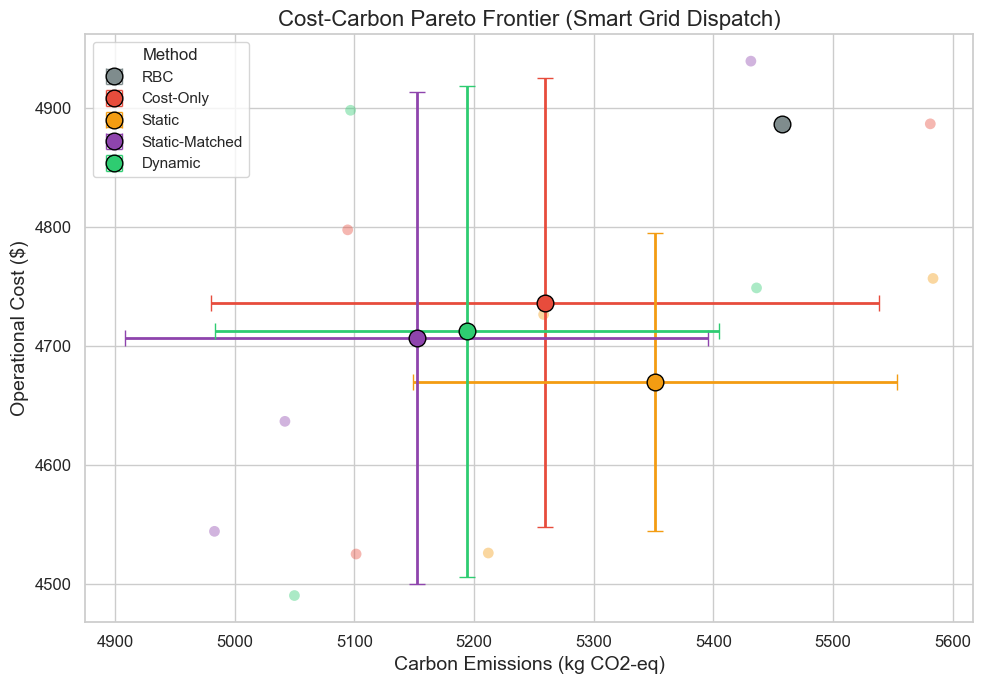

In [6]:
summary_avg = df_results.groupby('method').agg(
    cost_mean=('cost', 'mean'), cost_std=('cost', 'std'),
    carbon_mean=('carbon', 'mean'), carbon_std=('carbon', 'std'),
).reindex([m for m in METHODS if m in df_results['method'].unique()]).reset_index()

fig, ax = plt.subplots(figsize=(10, 7))
for _, row in df_results.iterrows():
    ax.scatter(row['carbon'], row['cost'], color=METHOD_COLORS.get(row['method'], '#3498db'),
               alpha=0.4, s=60, edgecolors='none')
for _, row in summary_avg.iterrows():
    ax.errorbar(row['carbon_mean'], row['cost_mean'], xerr=row['carbon_std'], yerr=row['cost_std'],
                fmt='o', markersize=12, label=row['method'], color=METHOD_COLORS.get(row['method'], '#3498db'),
                capsize=6, elinewidth=2, markeredgecolor='black', markeredgewidth=1)
ax.set_xlabel('Carbon Emissions (kg CO2-eq)')
ax.set_ylabel('Operational Cost ($)')
ax.set_title('Cost-Carbon Pareto Frontier (Smart Grid Dispatch)')
ax.legend(title="Method", frameon=True)
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'pareto_frontier.png', dpi=300)
plt.show()

## 5. Training curves
Episode reward vs training steps, mean ± std across seeds. Rewards are on **different scales** for each method
(the carbon term adds to the penalty), so compare the *shape* — convergence speed and stability — not the level.

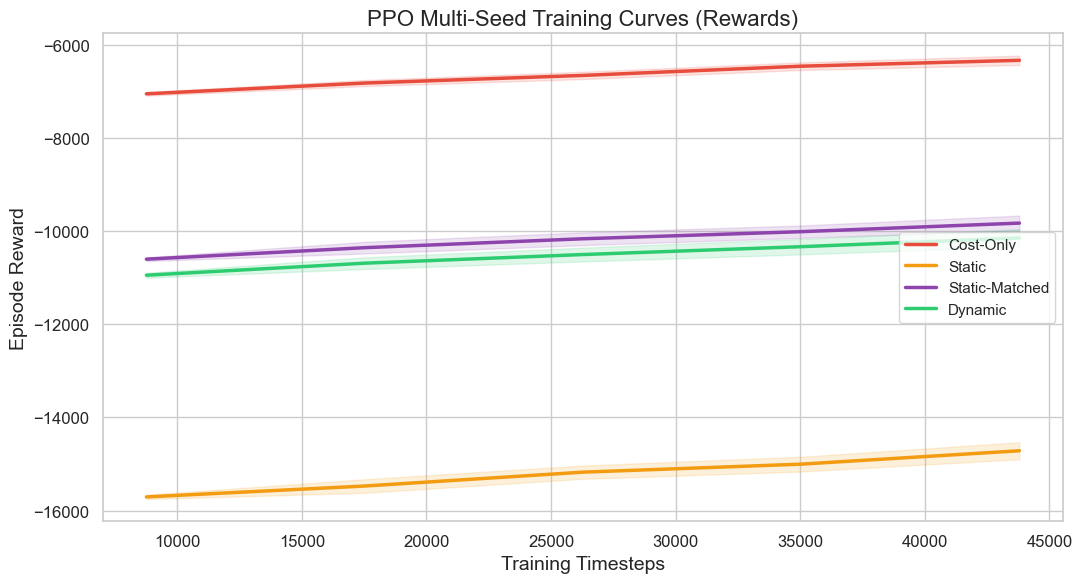

In [7]:
fig, ax = plt.subplots(figsize=(11, 6))
for method in PPO_METHODS:
    seed_logs = []
    for seed in SEEDS:
        log_path = TABLES_DIR / f"{run_name(method, seed)}_train_log.csv"
        if log_path.exists():
            seed_logs.append(pd.read_csv(log_path))
    if not seed_logs:
        continue

    # Align by episode across the seeds that actually have logs
    min_len = min(len(df) for df in seed_logs)
    aligned = np.column_stack([df['reward'].iloc[:min_len].values for df in seed_logs])
    steps = seed_logs[0]['step'].iloc[:min_len].values
    mean_r, std_r = aligned.mean(axis=1), aligned.std(axis=1)

    ax.plot(steps, mean_r, label=method, color=METHOD_COLORS[method], linewidth=2.5)
    ax.fill_between(steps, mean_r - std_r, mean_r + std_r, color=METHOD_COLORS[method], alpha=0.15)

ax.set_xlabel('Training Timesteps')
ax.set_ylabel('Episode Reward')
ax.set_title('PPO Multi-Seed Training Curves (Rewards)')
ax.legend(frameon=True)
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'training_curves.png', dpi=300)
plt.show()

## 6. Training curves in cost and carbon
Because rewards are not comparable across methods, the same logs plotted in the two physical units are a fairer
view of what each agent learned over training.

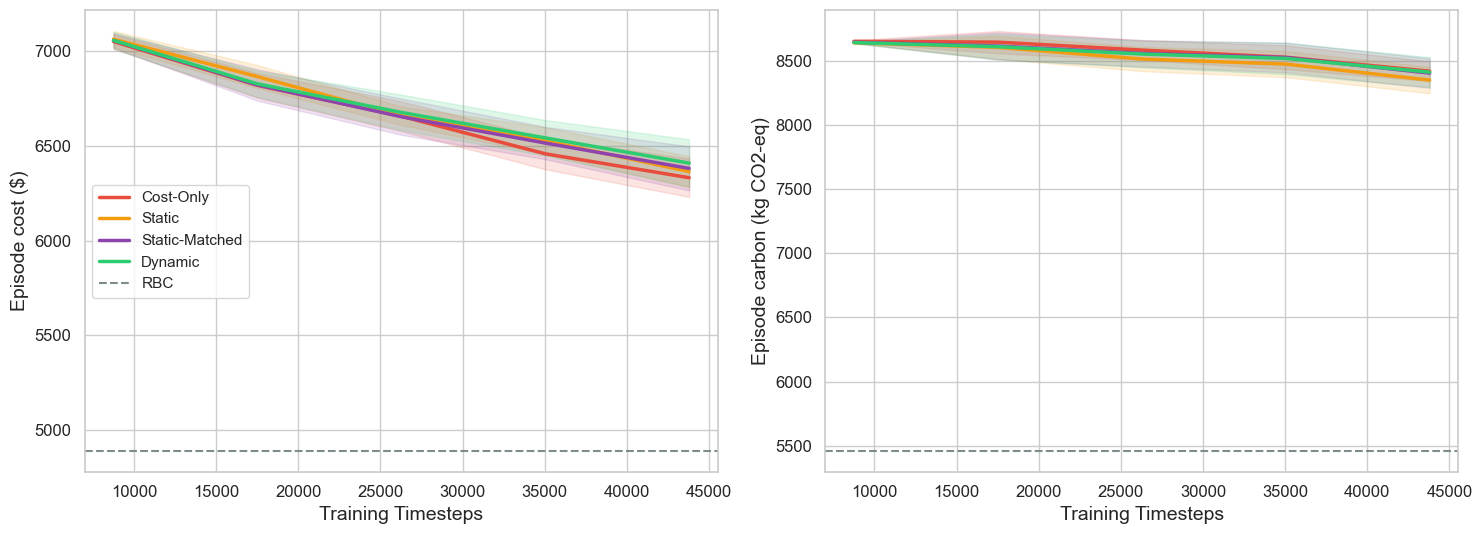

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for method in PPO_METHODS:
    logs = [pd.read_csv(p) for p in (TABLES_DIR / f"{run_name(method, s)}_train_log.csv" for s in SEEDS) if p.exists()]
    if not logs:
        continue
    n = min(len(df) for df in logs)
    steps = logs[0]['step'].iloc[:n].values
    for ax, col in zip(axes, ['cost', 'carbon']):
        vals = np.column_stack([df[col].iloc[:n].values for df in logs])
        ax.plot(steps, vals.mean(axis=1), label=method, color=METHOD_COLORS[method], linewidth=2.5)
        ax.fill_between(steps, vals.mean(axis=1) - vals.std(axis=1), vals.mean(axis=1) + vals.std(axis=1),
                        color=METHOD_COLORS[method], alpha=0.15)
for ax, col in zip(axes, ['cost', 'carbon']):
    ax.axhline(df_results.loc[df_results['method'] == 'RBC', col].mean(), color=METHOD_COLORS['RBC'],
               linestyle='--', label='RBC')
    ax.set_xlabel('Training Timesteps')
axes[0].set_ylabel('Episode cost ($)')
axes[1].set_ylabel('Episode carbon (kg CO2-eq)')
axes[0].legend(frameon=True)
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'training_curves_cost_carbon.png', dpi=300)
plt.show()